# Assignment 4
Eric Liu

[GitHub repository](https://github.com/yericliu/Assignment-3-4)

## Part 1
I use CIFAR-10 training images scaled to $[-1,1]$. The diffusion model learns to predict the noise added to each image. The energy model learns to give real images lower energy than samples obtained by Langevin updates. The API uses the saved weights to generate one RGB image per request.

C:\Users\Administrator\Downloads\Assignment4\.venv313\Lib\site-packages\fastapi\testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


/generate-diffusion 200 (32, 32)


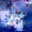

/generate-energy 200 (32, 32)


C:\Users\Administrator\Downloads\Assignment4\.venv313\Lib\site-packages\torch\autograd\graph.py:865: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\cuda\CublasHandlePool.cpp:330.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


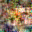

In [1]:
from io import BytesIO
from fastapi.testclient import TestClient
from PIL import Image
from IPython.display import display
from app.main import app

with TestClient(app) as client:
    for route in ["/generate-diffusion", "/generate-energy"]:
        response = client.get(route)
        response.raise_for_status()
        assert response.headers["content-type"] == "image/png"
        image = Image.open(BytesIO(response.content))
        assert image.mode == "RGB" and image.size == (32, 32)
        print(route, response.status_code, image.size)
        display(image)

## Q1
For an even embedding dimension $d$, I use pairs of sine and cosine values. For pair $k=0,\ldots,d/2-1$, the frequency is $\omega_k=10000^{-2k/d}$. The two coordinates are
$$e_{2k}(t)=\sin(t\omega_k),\qquad e_{2k+1}(t)=\cos(t\omega_k).$$
The first pair changes the fastest as the timestep increases.

## Q2
For $d=8$, the exponents $-2k/8$ are $0,-1/4,-1/2,-3/4$. Raising 10000 to those powers gives $1,0.1,0.01,0.001$. At $t=1$ these are also the angles in radians. Taking the sine and cosine of each in order gives approximately
$$[0.841471,\ 0.540302,\ 0.099833,\ 0.995004,\ 0.010000,\ 0.999950,\ 0.001000,\ 1.000000].$$

## Q3
Both methods turn an index into a vector using sine and cosine at different frequencies. In a transformer, each token gets an encoding for its position in the sequence. In a diffusion model, the whole image gets a time embedding for its current noise step. The denoising network uses it to decide how to interpret the noisy image.

## Q4
Each block halves the height and width. One side goes from $64$ to $32$, then $16$, then $8$. The bottleneck resolution is $8\times8$.

## Q5
I draw Gaussian noise $\epsilon$ and construct $x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\epsilon$. The U-Net takes $x_t$ and $t$ and returns a predicted noise tensor $\hat\epsilon$ with the same shape as the image. Since I know the noise I added, I can train the network with $L=\mathrm{mean}[(\hat\epsilon-\epsilon)^2]$, averaging over the batch, channels and pixels.

## Q6
a. For $y=x^2+3x$, $dy/dx=2x+3$. At $x=2$, the derivative is $4+3=7$.

b. With tracking turned off, none of the inputs in this example requires a gradient. The output has no gradient history, so calling backward raises a RuntimeError.

c. The default is `requires_grad=False`, as shown in the [torch.tensor documentation](https://docs.pytorch.org/docs/stable/generated/torch.tensor.html).

In [2]:
import torch

x = torch.tensor([2.0], requires_grad=True)
y = x**2 + 3*x
y.backward()
print("x.grad =", x.grad)

x = torch.tensor([2.0], requires_grad=False)
y = x**2 + 3*x
try:
    y.backward()
except RuntimeError as error:
    print(error)

x.grad = tensor([7.])
element 0 of tensors does not require grad and does not have a grad_fn


## Q7
a. In the original code, only $x$ requires a gradient. Its gradient is 7, and `w.grad` is `None`.

b. For $y=w_0x^2+w_1x$, the partial derivatives are $\partial y/\partial w_0=x^2=4$ and $\partial y/\partial w_1=x=2$. I turn on tracking for $w$ before computing $y$ again.

c. Omitting the flag leaves gradient tracking off for the new tensor by default.

In [3]:
x = torch.tensor([2.0], requires_grad=True)
w = torch.tensor([1.0, 3.0])
y = w[0]*x**2 + w[1]*x
y.backward()
print("x.grad =", x.grad)
print("w.grad =", w.grad)

w = torch.tensor([1.0, 3.0], requires_grad=True)
x.grad = None
y = w[0]*x**2 + w[1]*x
y.backward()
print("w.grad =", w.grad)

x.grad = tensor([7.])
w.grad = None
w.grad = tensor([4., 2.])


## Q8
Calling `detach()` breaks the link from $z$ to $y$. Since $w$ is then computed using only $z$ and a constant, backward has no graph to follow. I use `clone()` to keep a separate tensor $z$ connected to $y$. Now $w=2(3x)=6x$, so $dw/dx=6$.

In [4]:
x = torch.tensor([1.0], requires_grad=True)
y = x*3
z = y.clone()
w = z*2
w.backward()
print("x.grad =", x.grad)

x.grad = tensor([6.])


## Q9
The first backward call adds $d(2x)/dx=2$ to `x.grad`. The second adds $d(3x)/dx=3$ to the same gradient, giving $2+3=5$. To get the gradient of the second expression alone, I clear `x.grad` before calling backward on it.

In [5]:
x = torch.tensor([1.0], requires_grad=True)
y1 = x*2
y1.backward()
print("After first backward:", x.grad)
y2 = x*3
y2.backward()
print("After second backward:", x.grad)

x.grad = None
y2 = x*3
y2.backward()
print("After clearing the gradient:", x.grad)

After first backward: tensor([2.])
After second backward: tensor([5.])
After clearing the gradient: tensor([3.])
